# Group Homework 3 · The GoMart report makeover
**Data Visualization · UEH · Session 3** · team notebook

| | |
|---|---|
| **Team** | *team name* · **team number** (from the LMS list): __ |
| **Status** | Formative: written feedback with the rubric in the brief. Task 0 is the first version of Module M3 of your project |
| **Submit** | File ▸ Download ▸ .ipynb as `GH3_TeamName.ipynb` + the evidence folder of Task 4, within 7 days on the LMS |

Read the brief *Group Homework 3* first. All GoMart data is simulated.

## Task 5 · One-page summary for the operations director (write this last)
**Big Idea:** *one complete sentence.*

*At most 100 words. The one-page figure is made in the last code cell of the notebook (it needs everything above);
after "Restart and run all", paste its image here.*

## Task 0 · Project: house style v0 and makeover plan (Module M3)
**Allocated project:** P__ · *title*

1. Put your `house_style.py` v0 in the cell below (palette in fixed order, sequential map, diverging map, fonts, number format).
2. Show the evidence: a swatch of your palette in colour, in greyscale and with simulated deuteranopia.
3. Makeover plan for one published chart from your domain: link, screenshot, critique table, photo of your hand sketch.

In [ ]:
# Task 0 · house_style.py v0 for your project (paste the file content here, then run it)
# PROJECT_PALETTE = [...]       # fixed order, one colour per category of your project
# SEQ_CMAP = "..."; DIV_CMAP = "..."
# def use_house_style(): ...

In [ ]:
# Task 0 · evidence: palette swatch in colour, greyscale, deuteranopia
# (use fig_to_rgb, to_grey and simulate_cvd from the Setup section below)

**Makeover plan.** Source (link, date accessed): ...

| # | What I see | Principle broken (name it) | Effect on the reader | My fix |
|---|---|---|---|---|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |
| 4 | | | | |

*Insert the photo of your hand sketch here.*

## Setup
Upload `gomart_orders_2025_clean.csv`, `gomart_districts.csv` and `gomart_targets_2025.csv`.
Run `gomart_bad_report.py` once (or open `gomart_bad_report.pdf`) to see the six charts you will audit.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import TwoSlopeNorm, to_rgb

GREY, LIGHT, DARK, BLUE, ORANGE = "#a3a29c", "#d9d8d3", "#52514e", "#2a78d6", "#eb6834"
ZONE_COLOR = {"Central": "#a9c9ef", "Inner": "#5b9be3", "Outer": "#1f4f8f"}   # ordered: light -> dark

In [2]:
from pathlib import Path
DATA = Path("../../data/raw")                    # inside our repository
if not (DATA / "gomart_orders_2025_clean.csv").exists():
    DATA = Path(".")                             # files uploaded next to the notebook (Colab, LMS)
orders = pd.read_csv(DATA / "gomart_orders_2025_clean.csv", parse_dates=["order_time"])
districts = pd.read_csv(DATA / "gomart_districts.csv")
targets = pd.read_csv(DATA / "gomart_targets_2025.csv")
orders = orders.merge(districts, on="district", how="left", validate="many_to_one")
orders["month"] = orders["order_time"].dt.strftime("%Y-%m")
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
orders["weekday"] = pd.Categorical(orders["order_time"].dt.strftime("%a"), categories=days, ordered=True)
orders["hour"] = orders["order_time"].dt.hour
tiers = ["none", "Silver", "Gold", "Platinum"]
orders["member_tier"] = pd.Categorical(orders["member_tier"], categories=tiers, ordered=True)
delivered = orders[orders["status"] == "delivered"]
print(orders.shape, "| orders without zone:", orders["zone"].isna().sum())

(5913, 16) | orders without zone: 0


Helper functions from Tutorial 3 (given):

In [3]:
def fig_to_rgb(fig):
    fig.canvas.draw()
    return np.asarray(fig.canvas.buffer_rgba())[..., :3] / 255

def to_grey(rgb):
    return np.asarray(rgb)[..., :3] @ np.array([0.299, 0.587, 0.114])

DEUTAN = np.array([[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413],
                   [-0.011820, 0.042940, 0.968881]])

def simulate_cvd(rgb, M=DEUTAN):
    lin = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    sim = np.clip(lin @ M.T, 0, 1)
    return np.where(sim <= 0.0031308, 12.92 * sim, 1.055 * sim ** (1 / 2.4) - 0.055)

## Task 1 · Audit the report
For each of the six charts: the task the chart should support (action + target), then at least four problems.

| Chart | Task it should support | Problem | Principle (name it) | Effect on the reader |
|---|---|---|---|---|
| 1 Orders by district | Compare the number of orders across the 10 districts and rank them (action: compare + rank; target: districts) | A pie with 10 slices of near-equal size (7.1% to 12.8%) | Effectiveness / expressiveness: angle and area are judged less accurately than position on a common scale (Cleveland & McGill) | The reader cannot tell whether Binh Thanh or Tan Binh is larger, and cannot see that the biggest district has 1.8 times the orders of the smallest |
| 1 | | The 10 slices use the `jet` rainbow and a separate 10-entry legend, and the slice labels repeat the legend | Colour job and short-term memory: ten colour-name pairs exceed the 4 to 7 items that working memory holds; colour carries no information because the district name is already the label | The reader jumps between legend and pie, and still loses track of which slice is which |
| 1 | | Slices are in alphabetical order (`sort_index`), not in order of size | Ordering: an ordered quantity needs an ordered layout; alphabetical order has no link to the task | The ranking, which is the point of the chart, is hidden; the reader has to sort ten percentages in their head |
| 1 | | `explode`, `shadow` and two-decimal percentages (`12.75%`) on every slice | Data-ink: decoration and false precision add ink that carries no information | The eye is pulled to the shadows and gaps, not to the size differences; the numbers are hard to scan |
| 1 | | Rainbow colours turn into a non-monotonic grey ramp, and several neighbours collapse for deuteranopia | Greyscale and colour-vision deficiency: lightness of `jet` is not monotonic and red-green pairs merge | In a black-and-white print or for a colour-blind reader, many slices cannot be told apart even with the legend |
| 2 Payments | | | | |
| 3 Delivery time | | | | |
| 4 Peak times | Identify peak ordering hours and days across the week to allocate staff and riders | Use rainbow colormap `cmap="jet"` for order volume | Expressiveness & Perceptually uniform map | Luminance $L^*$ changes unpredictably, creating artificial boundaries; in greyscale or for colour-blind viewers, the data peak (Tuesday 19:00) turns dark, distorting information |
| 4 | | Days of the week ordered alphabetically A-Z (*Friday, Monday...*) | Expressiveness & Gestalt Continuity | Breaks the natural chronological time sequence, forcing readers to search item-by-item, increasing cognitive load |
| 4 | | Generic topic title: `"Orders heatmap"` | Direct attention & Action title | Fails to convey the main message; managers must spend time manually scanning to find peak hours |
| 4 | | Colorbar lacks measurement unit and is not anchored at `vmin=0` | Clutter & Encoding Integrity | Readers cannot tell whether measurement unit is order count or revenue; unanchored zero distorts density comparison |
| 5 Targets | | | | |
| 6 Basket by tier | | | | |

## Task 2 · Redesign
### Chart 1 · Orders by district
*Task:* compare the number of orders across the 10 districts and rank them.  *Why this chart:* a horizontal bar chart sorted by size puts every value on one common baseline (position, the most accurate channel), and the district names can sit next to the bars, so there is no legend.

*Choices:* zero baseline; sorted from largest to smallest; grey for the eight other districts and one highlight colour for the two largest; direct value labels (count and share); no gridlines, no frame, no legend; the title states the finding.

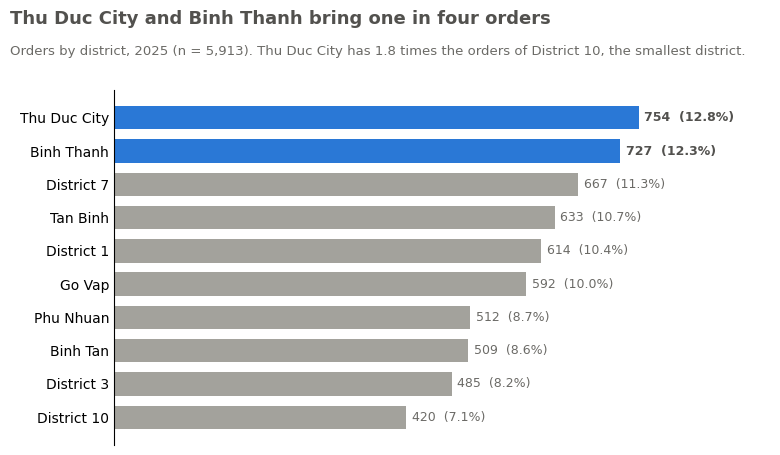

In [ ]:
# Chart 1 · Orders by district: sorted horizontal bars, grey + highlight
counts = orders["district"].value_counts()                  # already sorted, largest first
share = counts / counts.sum() * 100
top2 = counts.index[:2]
top2_share = counts[top2].sum() / counts.sum() * 100
ratio = counts.iloc[0] / counts.iloc[-1]

fig, ax = plt.subplots(figsize=(8, 5))
colors = [BLUE if d in top2 else GREY for d in counts.index]
bars = ax.barh(counts.index, counts.values, color=colors, height=0.7)
ax.invert_yaxis()                                           # largest at the top
for b, d in zip(bars, counts.index):
    ax.text(b.get_width() + 8, b.get_y() + b.get_height() / 2,
            f"{counts[d]:,}  ({share[d]:.1f}%)", va="center", fontsize=9,
            color=DARK if d in top2 else "#6b6a66", fontweight="bold" if d in top2 else "normal")
ax.set_xlim(0, counts.max() * 1.25)
ax.set_xticks([])                                           # values are labelled directly
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.tick_params(axis="y", length=0)

fig.suptitle(f"{top2[0]} and {top2[1]} bring one in four orders",
             x=0.02, ha="left", fontsize=13, fontweight="bold", color=DARK)
fig.text(0.02, 0.89, f"Orders by district, 2025 (n = {counts.sum():,}). {top2[0]} has {ratio:.1f} times the orders of {counts.index[-1]}, the smallest district.",
         ha="left", fontsize=9.5, color="#6b6a66")
fig.subplots_adjust(top=0.82, left=0.15, right=0.97)
fig1 = fig                                                  # kept for the Task 3 test
plt.show()

In [ ]:
# Check: every number in the Chart 1 title and the evidence behind it
print(counts.to_frame("orders").assign(share_pct=share.round(2)))
print("Total orders:", counts.sum())
print(f"Top two ({top2[0]} + {top2[1]}): {counts[top2].sum()} orders = {top2_share:.2f}% of all  ->  title says 'one in four' (25%)")
print(f"Fewest: {counts.index[-1]} with {counts.iloc[-1]} orders ({share.iloc[-1]:.2f}%); the largest is {ratio:.2f} times larger")
assert round(top2_share) == 25 and counts.index[-1] == "District 10"

              orders  share_pct
district                       
Thu Duc City     754      12.75
Binh Thanh       727      12.29
District 7       667      11.28
Tan Binh         633      10.71
District 1       614      10.38
Go Vap           592      10.01
Phu Nhuan        512       8.66
Binh Tan         509       8.61
District 3       485       8.20
District 10      420       7.10
Total orders: 5913
Top two (Thu Duc City + Binh Thanh): 1481 orders = 25.05% of all  ->  title says 'one in four' (25%)
Fewest: District 10 with 420 orders (7.10%); the largest is 1.80 times larger


### Chart 2 · Payments
*Task:* ...  *Why this chart:* ...

In [ ]:
# TODO: write your code here

### Chart 3 · Delivery time
*Task:* identify where deliveries are slow, and compare each district's delivery time with its distance to the hub.  
*Why this chart:* horizontal bars sorted by time put the slowest district on top and start at zero, so each bar's length is honest; the distance in each label answers the second half of the task without a second chart.

*Summary:* the median of delivered orders (cancelled orders have no delivery time). The mean gives the same ranking and differs by less than half a minute (output below), so the choice does not change the finding; the median describes the typical order.  
*Colour:* grey for every district, blue only for the districts slower than the city median.

In [4]:
# Chart 3 · the numbers in the title and subtitle, checked here
d3 = (delivered.groupby("district")
               .agg(minutes=("delivery_min", "median"), mean=("delivery_min", "mean"),
                    km=("km_to_hub", "first"))
               .sort_values("minutes"))
city = delivered["delivery_min"].median()
slow = d3["minutes"] > city                                   # blue: slower than the city median
per_km = delivered["delivery_min"].cov(delivered["km_to_hub"]) / delivered["km_to_hub"].var()
top, base = d3.index[-1], d3.index[0]

print(d3.round(1).to_string(), "\n")
print("delivered orders without a delivery time:", delivered["delivery_min"].isna().sum())
print(f"largest gap between mean and median: {(d3['mean'] - d3['minutes']).abs().max():.2f} min;",
      "same ranking:", list(d3.sort_values("mean").index) == list(d3.index))
print(f"city median: {city:.1f} min")
print(f"{top} / {base}: {d3.loc[top, 'minutes']:.1f} / {d3.loc[base, 'minutes']:.1f} = "
      f"{d3.loc[top, 'minutes'] / d3.loc[base, 'minutes']:.2f}")
print(f"minutes per extra km: {per_km:.2f}")
print("blue districts = the four farthest from the hub:",
      set(d3.index[slow]) == set(d3["km"].nlargest(4).index))

              minutes  mean    km
district                         
District 1       26.7  26.7   2.1
District 3       29.3  29.1   2.8
District 10      30.7  30.7   3.5
Phu Nhuan        32.2  32.2   4.0
Binh Thanh       33.7  33.6   4.6
Tan Binh         34.9  35.2   5.2
District 7       41.2  41.2   7.5
Go Vap           42.1  41.9   7.9
Binh Tan         49.7  49.6  10.8
Thu Duc City     51.7  51.7  11.5 

delivered orders without a delivery time: 6
largest gap between mean and median: 0.26 min; same ranking: True
city median: 36.3 min
Thu Duc City / District 1: 51.7 / 26.7 = 1.94
minutes per extra km: 2.61
blue districts = the four farthest from the hub: True


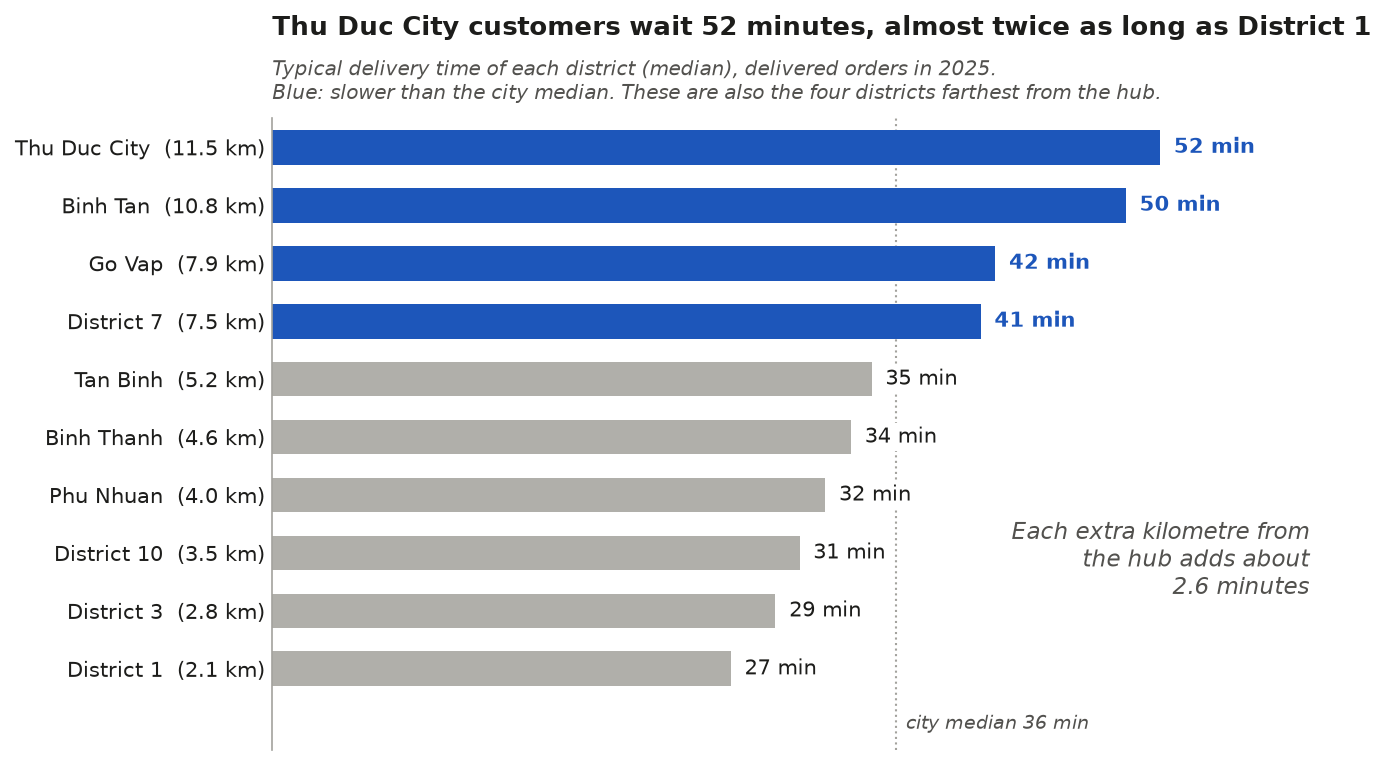

In [5]:
# Chart 3 · redesign: slowest district on top, blue only where delivery is slower than the city median
INK, NOTE, AXIS = "#1d1d1b", "#52514e", "#a3a29d"              # same greys as our GH2 charts
BAR, HIGHLIGHT = "#b0afaa", "#1d56ba"

fig3, ax = plt.subplots(figsize=(9, 5.2), dpi=150)
names = [f"{d}  ({km:.1f} km)" for d, km in zip(d3.index, d3["km"])]
bars = ax.barh(names, d3["minutes"], height=0.6, color=np.where(slow, HIGHLIGHT, BAR))
for bar, minutes, is_slow in zip(bars, d3["minutes"], slow):
    ax.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2, f"{minutes:.0f} min", va="center",
            fontsize=10, fontweight="bold" if is_slow else "normal", color=HIGHLIGHT if is_slow else INK,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5))  # readable over the median line
ax.axvline(city, color=AXIS, lw=1, ls=":", zorder=0)
ax.text(city + 0.6, -0.95, f"city median {city:.0f} min", fontsize=9, style="italic", color=NOTE, va="center")
ax.text(0.99, 0.30, f"Each extra kilometre from\nthe hub adds about\n{per_km:.1f} minutes",
        transform=ax.transAxes, ha="right", va="center", fontsize=11, style="italic", color=NOTE)

ax.set_xlim(0, d3["minutes"].max() * 1.18)                     # bars start at zero
ax.set_ylim(-1.4, len(d3) - 0.5)                               # room under the bars for the median label
ax.set_xticks([])                                              # every bar carries its own number
ax.tick_params(axis="y", length=0, labelsize=10, labelcolor=INK)
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.spines["left"].set_color(AXIS)
ax.set_title(f"{top} customers wait {d3.loc[top, 'minutes']:.0f} minutes, almost twice as long as {base}",
             loc="left", fontsize=12.5, fontweight="bold", color=INK, pad=40)
ax.text(0, 1.02, "Typical delivery time of each district (median), delivered orders in 2025.\n"
        "Blue: slower than the city median. These are also the four districts farthest from the hub.",
        transform=ax.transAxes, fontsize=9.5, style="italic", color=NOTE, va="bottom")
fig3.tight_layout()
plt.show()

### Chart 4 · Peak times
*Task:* Identify peak ordering hours and days across the week to allocate staff and delivery riders efficiently.  </br>
*Why this chart:* A 2D heatmap with a chronological calendar layout (Mon–Sun) and a single-hue sequential colormap (`Blues`) encodes order volume into monotonic lightness ($L^*$), making peak operational rush hours instantly identifiable without clutter or rainbow distortion.

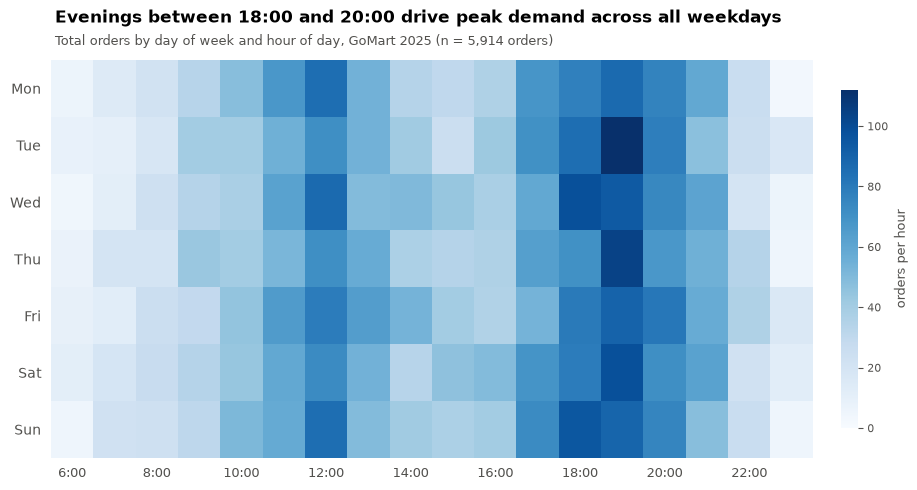

In [ ]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
orders["weekday"] = pd.Categorical(orders["order_time"].dt.strftime("%a"), categories=days, ordered=True)
orders["hour"] = orders["order_time"].dt.hour

t = orders.pivot_table(index="weekday", columns="hour", values="order_id", aggfunc="count", observed=False).fillna(0)

fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(t.values, cmap="Blues", aspect="auto", vmin=0)

ax.set_yticks(range(len(t.index)))
ax.set_yticklabels(t.index, fontsize=10, color=DARK)

tick_indices = list(range(0, len(t.columns), 2))
ax.set_xticks(tick_indices)
ax.set_xticklabels([f"{t.columns[i]}:00" for i in tick_indices], fontsize=9, color=DARK)

cbar = fig.colorbar(im, ax=ax, pad=0.03, shrink=0.85)
cbar.set_label("orders per hour", fontsize=9, color=DARK)
cbar.ax.tick_params(labelsize=8, colors=DARK)
cbar.outline.set_visible(False)

for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(left=False, bottom=False)

fig.text(0.06, 1.05, "Evenings between 18:00 and 20:00 drive peak demand across all weekdays",
         fontsize=12, weight="bold", color="black", ha="left")
fig.text(0.06, 1.00, "Total orders by day of week and hour of day, GoMart 2025 (n = 5,914 orders)",
         fontsize=9.5, color=DARK, ha="left")

plt.tight_layout()
plt.show()

In [32]:
# Check numbers for Chart 4 Action Title
total_orders = orders.shape[0]
evening_orders = t.loc[:, 18:20].sum().sum()
evening_pct = evening_orders / total_orders * 100
peak_day, peak_h = t.stack().idxmax(), t.columns[t.values.argmax() % t.shape[1]]
peak_val = t.stack().max()

print(f"Total orders: {total_orders:,}")
print(f"Orders between 18:00-20:00: {evening_orders:,} ({evening_pct:.1f}% of all orders)")
print(f"Single highest cell: {peak_day} at {peak_h}:00 with {peak_val:.0f} orders")

Total orders: 5,913
Orders between 18:00-20:00: 1,780 (30.1% of all orders)
Single highest cell: ('Tue', np.int32(19)) at 19:00 with 112 orders


### Chart 5 · Targets
**Task:** Compare monthly actual orders against targets for Central, Inner, and Outer zones to identify underperforming months.

**Why this chart:** Three aligned diverging bar charts with a shared Y-axis enable accurate comparisons across zones. A zero reference line and signed value labels make shortfalls and surpluses easy to identify.

In [1]:

# Chart 5 - Data preparation
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find the data folder
candidates = [
    Path("data/raw"),
    Path("../../data/raw"),
    Path.cwd() / "data/raw",
]

data_dir = next(
    (p for p in candidates if
     (p / "gomart_targets_2025.csv").exists()),
    None
)
if data_dir is None:
    raise FileNotFoundError("Cannot find data/raw")

orders5 = pd.read_csv(
    data_dir / "gomart_orders_2025_clean.csv",
    parse_dates=["order_time"]
)
districts5 = pd.read_csv(
    data_dir / "gomart_districts.csv"
)
targets5 = pd.read_csv(
    data_dir / "gomart_targets_2025.csv"
)

# Join orders with their zones
orders5 = orders5.merge(
    districts5[["district", "zone"]],
    on="district",
    how="left",
    validate="many_to_one"
)
orders5["month"] = orders5["order_time"].dt.strftime("%Y-%m")

# Count monthly orders by zone
actual5 = (
    orders5.groupby(["zone", "month"])
    .size()
    .reset_index(name="actual_orders")
)

# Compare actual orders with targets
chart5 = targets5.merge(
    actual5,
    on=["zone", "month"],
    how="left",
    validate="one_to_one"
)

chart5["actual_orders"] = (
    chart5["actual_orders"].fillna(0).astype(int)
)
chart5["gap"] = (
    chart5["actual_orders"] - chart5["target_orders"]
)

zone_order5 = ["Central", "Inner", "Outer"]
chart5["zone"] = pd.Categorical(
    chart5["zone"],
    categories=zone_order5,
    ordered=True
)
chart5 = chart5.sort_values(["zone", "month"])

assert len(chart5) == 36
assert chart5["zone"].notna().all()

print(chart5.to_string(index=False))
print("\nTotal gap by zone:")
print(chart5.groupby("zone", observed=True)["gap"].sum())


   zone   month  target_orders  actual_orders  gap
Central 2025-01            116            110   -6
Central 2025-02            117            105  -12
Central 2025-03            123            131    8
Central 2025-04            125            143   18
Central 2025-05            125            137   12
Central 2025-06            136            137    1
Central 2025-07            137            101  -36
Central 2025-08            143            145    2
Central 2025-09            151            122  -29
Central 2025-10            151            123  -28
Central 2025-11            151            133  -18
Central 2025-12            157            132  -25
  Inner 2025-01            196            181  -15
  Inner 2025-02            192            177  -15
  Inner 2025-03            205            240   35
  Inner 2025-04            211            214    3
  Inner 2025-05            211            223   12
  Inner 2025-06            223            220   -3
  Inner 2025-07            232 

### Chart 5 – Targets: Audit

**Task:** Identify which zones and months missed their order targets in 2025.

| Problem | Violated principle | Effect on the reader |
|---|---|---|
| Different Y-axis scales across zones | Effectiveness | Readers may misjudge the relative size of target gaps. |
| Red and green bars indicate performance | Colour-vision deficiency | Some readers may struggle to distinguish positive and negative gaps. |
| Generic title without a takeaway | Preattentive attention | Readers must inspect all three panels to find the most important result. |
| Important shortfalls are not highlighted | Effectiveness | The largest negative gaps are difficult to identify quickly. |
| Repeated labels and unnecessary borders | Data-ink | Visual clutter reduces readability. |

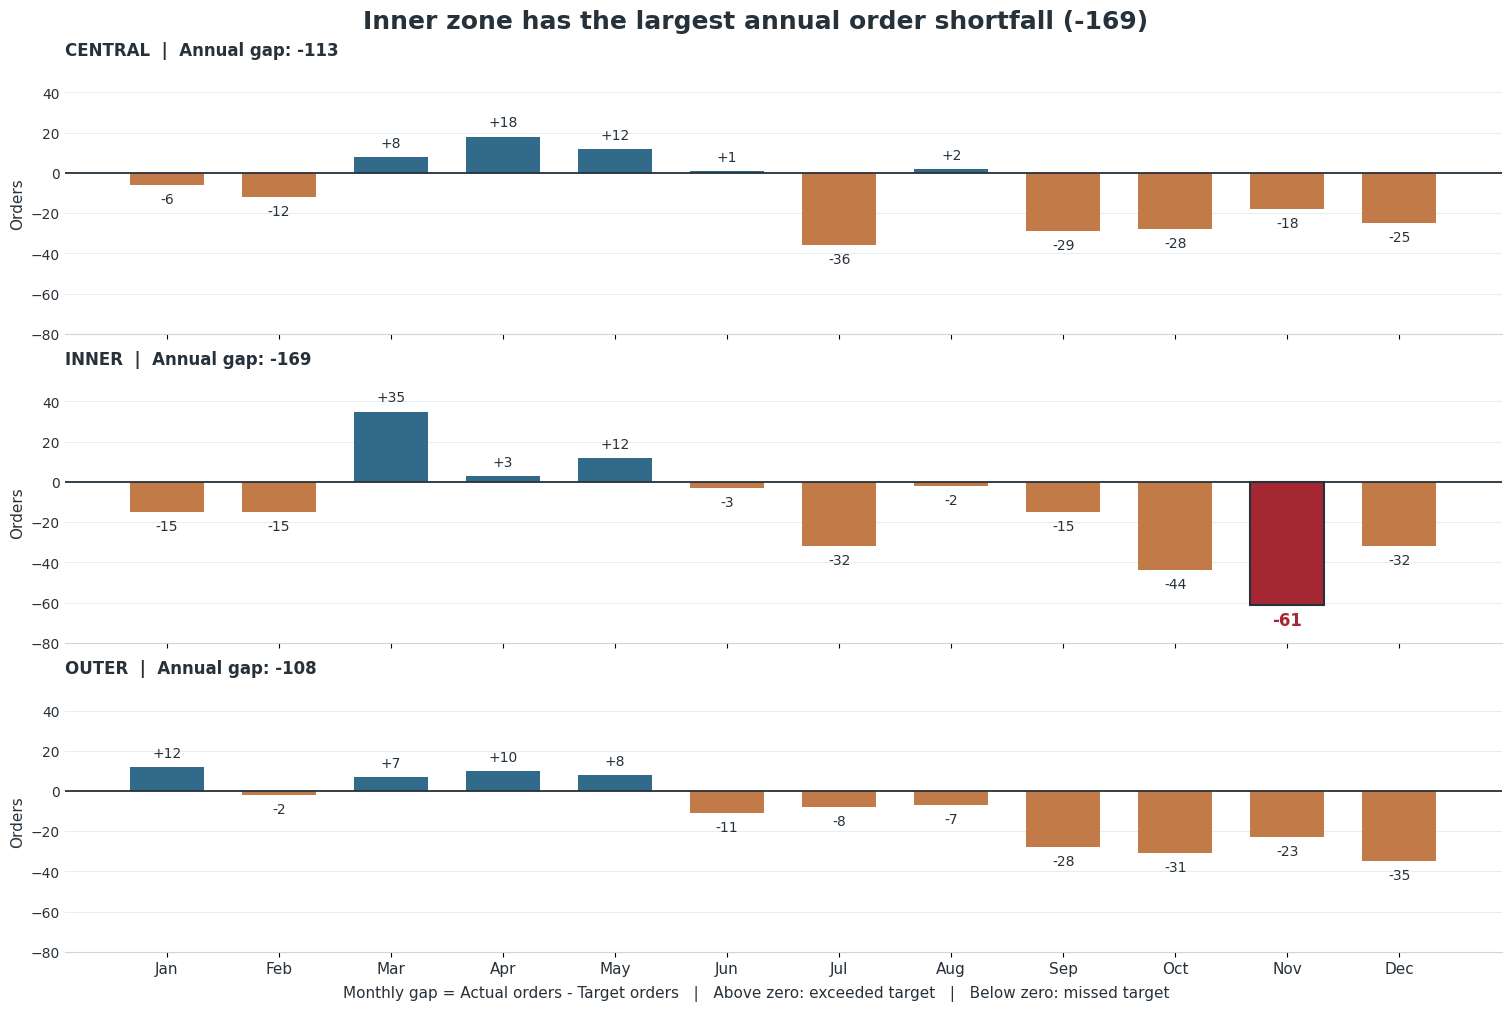

In [2]:

# ============================================================
# CHART 5 - FINAL REDESIGN | GoMart Operations Report 2025
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Data from Chart 5 preparation cell
months5 = sorted(chart5["month"].unique())
x5 = np.arange(len(months5))

# Accessible color palette
POS = "#326A8A"       # Above target
NEG = "#C17A48"       # Below target
FOCUS = "#A52734"     # Largest monthly shortfall
TEXT = "#27313A"
GRID = "#E8EDF0"

# Automatically identify the largest monthly shortfall
worst5 = chart5.loc[chart5["gap"].idxmin()]
worst_zone5 = str(worst5["zone"])
worst_month5 = str(worst5["month"])
worst_gap5 = int(worst5["gap"])

# Annual gap by zone
annual5 = (
    chart5.groupby("zone", observed=True)["gap"]
    .sum()
)
annual_worst5 = annual5.idxmin()
annual_gap5 = int(annual5.min())

# Shared Y-axis range for fair comparisons
ymin5 = min(-80, int(chart5["gap"].min()) - 10)
ymax5 = max(50, int(chart5["gap"].max()) + 10)

fig5, axes5 = plt.subplots(
    3, 1,
    figsize=(15, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

for ax, zone in zip(axes5, zone_order5):

    subset = chart5[chart5["zone"] == zone]

    values = (
        subset.set_index("month")
        .reindex(months5)["gap"]
        .to_numpy()
        .astype(int)
    )

    colors = [
        FOCUS if (
            zone == worst_zone5
            and month == worst_month5
        )
        else POS if value >= 0 else NEG
        for month, value in zip(months5, values)
    ]

    bars = ax.bar(
        x5, values,
        width=0.66,
        color=colors,
        zorder=3
    )

    # Zero reference line
    ax.axhline(
        0,
        color=TEXT,
        linewidth=1.3,
        zorder=4
    )

    ax.set_ylim(ymin5, ymax5)

    # Zone heading with annual gap
    ax.set_title(
        f"{zone.upper()}  |  Annual gap: {int(annual5[zone]):+d}",
        loc="left",
        fontsize=12,
        fontweight="bold",
        color=TEXT,
        pad=12
    )

    ax.set_ylabel(
        "Orders",
        fontsize=11,
        color=TEXT
    )

    # Subtle grid
    ax.grid(
        axis="y",
        color=GRID,
        linewidth=0.8,
        zorder=0
    )
    ax.set_axisbelow(True)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_color("#CED5DB")
    ax.tick_params(
        axis="y",
        length=0,
        labelsize=10,
        colors=TEXT
    )

    # Signed value labels
    for month, bar, value in zip(months5, bars, values):

        is_focus = (
            zone == worst_zone5
            and month == worst_month5
        )

        ax.annotate(
            f"{value:+d}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                value
            ),
            xytext=(
                0,
                5 if value >= 0 else -5
            ),
            textcoords="offset points",
            ha="center",
            va="bottom" if value >= 0 else "top",
            fontsize=12 if is_focus else 10,
            fontweight="bold" if is_focus else "normal",
            color=FOCUS if is_focus else TEXT
        )

        if is_focus:
            bar.set_edgecolor(TEXT)
            bar.set_linewidth(1.5)

# Highlight the largest shortfall
if zone == worst_zone5:
    focus_x = months5.index(worst_month5)

    ax.annotate(
        "WORST MONTH",
        xy=(focus_x, worst_gap5),
        xytext=(0, -20),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=9,
        fontweight="bold",
        color=FOCUS
    )

# Month labels
axes5[-1].set_xticks(x5)
axes5[-1].set_xticklabels(
    [
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug",
        "Sep", "Oct", "Nov", "Dec"
    ],
    fontsize=11,
    color=TEXT
)

# Main takeaway
fig5.suptitle(
    f"{annual_worst5} zone has the largest annual "
    f"order shortfall ({annual_gap5:+d})",
    fontsize=18,
    fontweight="bold",
    color=TEXT
)

# Reading guide
fig5.supxlabel(
    "Monthly gap = Actual orders - Target orders"
    "   |   Above zero: exceeded target"
    "   |   Below zero: missed target",
    fontsize=11,
    color=TEXT
)

plt.show()


### Chart 5 – Targets: Redesign

**Task:** Compare monthly actual orders against targets across Central, Inner, and Outer zones.

**Chart choice:** Three aligned diverging bar charts with a shared Y-axis.

**Why this chart:** The common zero baseline, consistent scale and signed labels allow readers to compare positive and negative gaps accurately without relying on colour alone.

**Key finding:** Inner has the largest annual order shortfall (−169 orders). Its largest monthly shortfall occurs in November (−61 orders).

**Design improvements:** Consistent axes, direct value labels, a blue–orange colour scheme, reduced visual clutter and a highlighted critical shortfall.

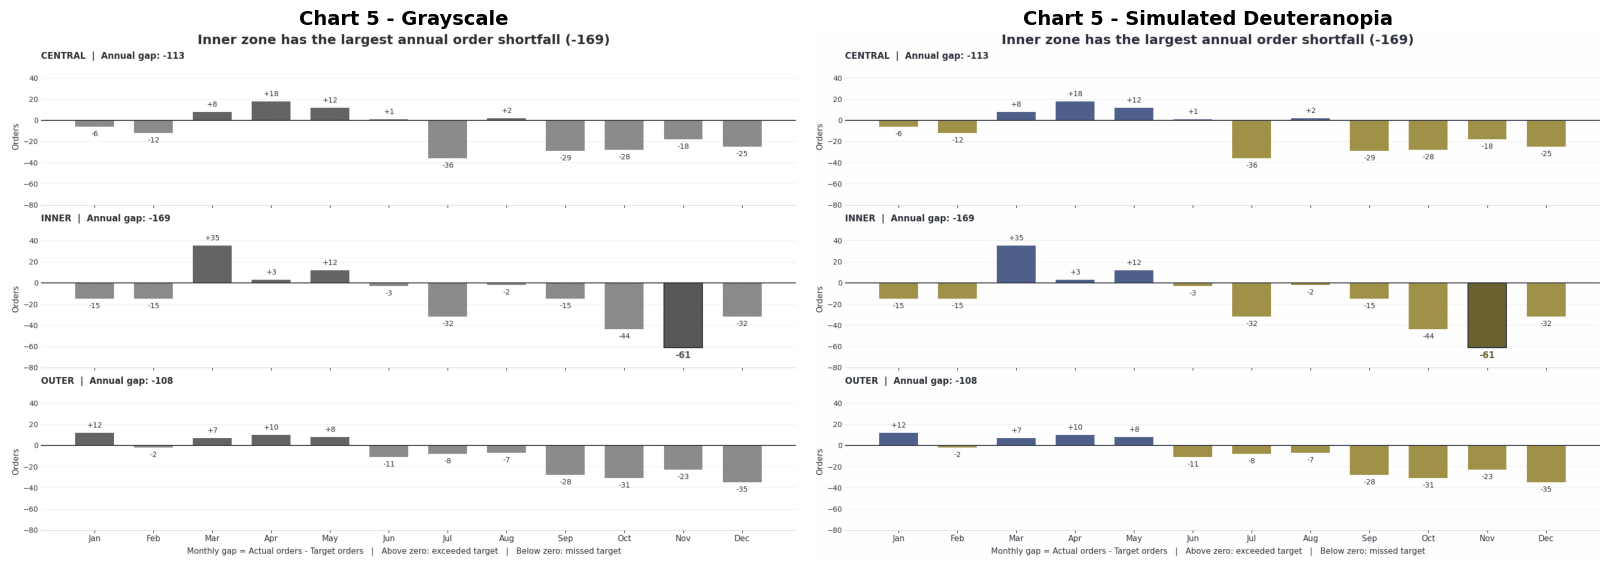

In [3]:

# ==================================================
# TASK 3 - CHART 5 ACCESSIBILITY TEST
# Grayscale + simulated deuteranopia
# ==================================================

import numpy as np
import matplotlib.pyplot as plt

# Capture the redesigned Chart 5
fig5.canvas.draw()
rgb5 = np.asarray(
    fig5.canvas.buffer_rgba()
)[..., :3].astype(float) / 255.0

# 1. Grayscale simulation (sRGB luminance)
linear5 = np.where(
    rgb5 <= 0.04045,
    rgb5 / 12.92,
    ((rgb5 + 0.055) / 1.055) ** 2.4
)

luminance5 = (
    0.2126 * linear5[..., 0]
    + 0.7152 * linear5[..., 1]
    + 0.0722 * linear5[..., 2]
)

gray5 = np.where(
    luminance5 <= 0.0031308,
    12.92 * luminance5,
    1.055 * luminance5 ** (1 / 2.4) - 0.055
)

# 2. Deuteranopia simulation
matrix5 = np.array([
    [0.367322, 0.860646, -0.227968],
    [0.280085, 0.672501, 0.047413],
    [-0.011820, 0.042940, 0.968881]
])

sim_linear5 = np.clip(
    linear5 @ matrix5.T, 0, 1
)

deuter5 = np.where(
    sim_linear5 <= 0.0031308,
    12.92 * sim_linear5,
    1.055 * sim_linear5 ** (1 / 2.4) - 0.055
)

# Display both tests
fig_test5, ax_test5 = plt.subplots(
    1, 2, figsize=(16, 6),
    constrained_layout=True
)

ax_test5[0].imshow(
    np.clip(gray5, 0, 1),
    cmap="gray",
    vmin=0,
    vmax=1
)
ax_test5[0].set_title(
    "Chart 5 - Grayscale",
    fontsize=14, fontweight="bold"
)

ax_test5[1].imshow(
    np.clip(deuter5, 0, 1)
)
ax_test5[1].set_title(
    "Chart 5 - Simulated Deuteranopia",
    fontsize=14, fontweight="bold"
)

for ax in ax_test5:
    ax.axis("off")

plt.show()


### Chart 5 – Accessibility Test Results

**Grayscale test:** Positive and negative gaps remain distinguishable through their positions relative to the zero baseline and signed numerical labels.

**Deuteranopia test:** The redesigned blue–orange palette remains visually distinguishable in the simulation. Readers can also use bar direction and numerical values to interpret performance.

**Accessibility improvements:** The original red–green encoding was replaced with blue and orange. Direct signed labels and a shared zero baseline were added to reduce dependence on colour.

**Conclusion:** Both simulations preserve the main information. Inner's November shortfall (−61 orders) remains identifiable, although small labels may be harder to read when the figure is reduced in size.

### Chart 6 · Basket by tier
*Task:* ...  *Why this chart:* ...

In [ ]:
# TODO: write your code here

In [ ]:
# TODO: write your code here

*Check: every number in your six titles, with the output that proves it.*

## Task 3 · Test for every reader
Greyscale and deuteranopia versions of all six redesigns. Then: one change you made because of a test.

Chart 1 grey values: highlight 0.42, other bars 0.63, gap 0.21
Deuteranopia grey values of highlight / other: [0.4  0.63]


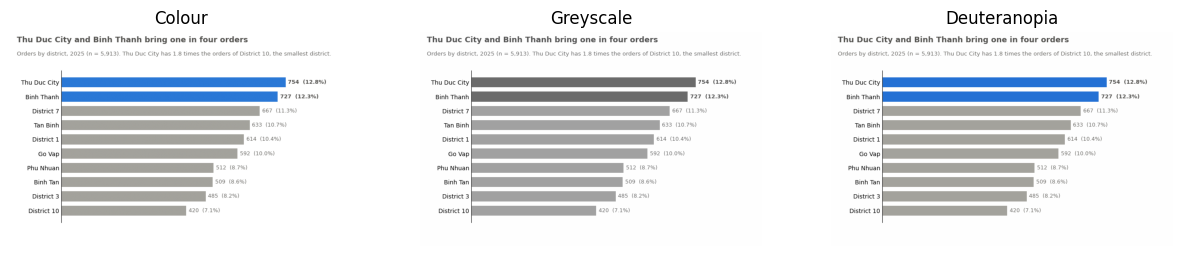

In [ ]:
# Task 3 · Chart 1 (Orders by district): colour, greyscale, deuteranopia
rgb = fig_to_rgb(fig1)
views = {"Colour": rgb, "Greyscale": np.dstack([to_grey(rgb)] * 3), "Deuteranopia": simulate_cvd(rgb)}
fig_t, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, img) in zip(axs, views.items()):
    ax.imshow(np.clip(img, 0, 1)); ax.set_title(name); ax.axis("off")
plt.show()
# lightness gap between the highlight and the grey bars (0 = same, 1 = black vs white)
g = lambda c: float(to_grey(np.array(to_rgb(c))))
print(f"Chart 1 grey values: highlight {g(BLUE):.2f}, other bars {g(GREY):.2f}, gap {g(GREY) - g(BLUE):.2f}")
sim = simulate_cvd(np.array([to_rgb(BLUE), to_rgb(GREY)]))
print("Deuteranopia grey values of highlight / other:", np.round(to_grey(sim), 2))
# TODO: the other five charts


*The change we made because of a test, and why:*

**Chart 1 (Orders by district):** passed both tests without a change. In greyscale the highlighted bars (grey value 0.42) are clearly darker than the other bars (0.63), and under deuteranopia the values stay 0.40 and 0.63, so the highlight does not rely on hue. This works because the design encodes "the two largest" with lightness plus position (sorted order) and direct labels, not with colour alone. The intern pie failed the same test: `jet` has a non-monotonic lightness and ten hues that merge.


## Task 4 · Perception experiment
### 4.1 Your stimulus sheet
Use **your team number** from the LMS list. Print the sheet (or put it in a form). Do not show the true values to anyone.

In [ ]:
def make_stimuli(team_number, path="stimulus_sheet.png"):
    """Perception experiment: one sheet with three panels (bars, pie, bubbles).
    Each panel shows five values A-E; the largest is marked with *. Values differ per panel
    and per team, so every team has its own experiment. Returns the true values (keep them secret)."""
    rng = np.random.default_rng(1000 + team_number)
    truth = {}
    fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
    for ax, kind in zip(axs, ["bars", "pie", "bubbles"]):
        v = np.round(rng.uniform(10, 90, 5))
        v[rng.integers(5)] = 100                                  # the reference value (only one)
        labels = [L + ("*" if val == 100 else "") for L, val in zip("ABCDE", v)]
        truth[kind] = dict(zip("ABCDE", v.astype(int).tolist()))
        if kind == "bars":
            ax.bar(labels, v, color="white", edgecolor="black")
            ax.set_yticks([]); ax.spines[["top", "right", "left"]].set_visible(False)
        elif kind == "pie":
            ax.pie(v, labels=labels, colors=["white"] * 5, wedgeprops=dict(edgecolor="black"),
                   startangle=90, counterclock=False)
        else:
            ax.scatter(range(5), [0] * 5, s=v / 100 * 2500, color="white", edgecolor="black")
            for i, L in enumerate(labels):
                ax.text(i, -0.55, L, ha="center")
            ax.set_ylim(-0.8, 0.8); ax.set_xlim(-0.7, 4.7); ax.axis("off")
        ax.set_title(f"Panel {['bars', 'pie', 'bubbles'].index(kind) + 1}")
    fig.text(0.5, 0.0, "The value marked * is 100. Estimate the other four values in each panel. "
             "Do not measure; answer within 30 seconds per panel.", ha="center", fontsize=10)
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.close(fig)
    return truth

In [ ]:
# Make the stimulus sheet for team 10. The true values stay in `truth`; they are not printed.
truth = make_stimuli(team_number=10)
print("Sheet saved as stimulus_sheet.png;", {k: len(v) for k, v in truth.items()}, "values per panel")

Sheet saved as stimulus_sheet.png; {'bars': 5, 'pie': 5, 'bubbles': 5} values per panel


### 4.2 Protocol (fill in before you collect)
- **Who:** people who do not take this course; each member collects at least 3 respondents and is recorded as `collector`. Respondents are coded R01, R02, ...; no names are recorded. *(Collector tuan-anh: R01-R03. Confirm that all three are outside the course.)*
- **How:** each respondent receives the same file `stimulus_sheet.png` privately (not in a group chat), so no one sees another person's answers.
- **Task:** estimate by eye the four unmarked values in each panel, taking the value marked \* as 100. In the pie panel the question is "how large is this slice compared with the slice marked \*", not a percentage of the whole pie. About 30 seconds per panel; no ruler.
- **No help:** the same wording for everyone; no hints, no true values, no comments on the answers.
- **Recording:** one answer per item, typed in the format `Panel 1: A=__ B=__ D=__ E=__`; a screenshot of each reply (name hidden, time visible) goes to `evidence/`. An answer given as a range is recorded as its middle; "about half" is recorded as 50.
- **Consent:** the purpose and the "no name" rule were stated before the respondent answered.

### 4.3 Your answers
Save your answers as `experiment_answers.csv` with the columns
`respondent, encoding, item, true, judged, collector` (one row per estimate; `collector` = the student ID of the team
member who collected it). Upload it next to the notebook.

In [ ]:
# answers = pd.read_csv("experiment_answers.csv")
# answers["log_error"] = np.log2(np.abs(answers["judged"] - answers["true"]) + 1 / 8)   # Cleveland & McGill (1984)
# print(answers.groupby("encoding")["log_error"].agg(["mean", "count"]).round(2))

In [ ]:
# Task 4.3: log_error for our own answers, summarised by encoding
answers = pd.read_csv("experiment_answers.csv")
answers["log_error"] = np.log2(np.abs(answers["judged"] - answers["true"]) + 1 / 8)
answers["abs_error"] = (answers["judged"] - answers["true"]).abs()
print("Respondents:", answers["respondent"].nunique(), "| estimates:", len(answers),
      "| collectors:", answers["collector"].unique().tolist())
summary = answers.groupby("encoding").agg(mean_log_error=("log_error", "mean"),
                                          mean_abs_error=("abs_error", "mean"), n=("log_error", "count")).round(2)
print(summary)

# 95% bootstrap interval over respondents (resample respondents, then average their errors)
rng = np.random.default_rng(0)
per_resp = answers.groupby(["encoding", "respondent"])["log_error"].mean().unstack()   # encoding x respondent
ci = {}
for enc in per_resp.index:
    vals = per_resp.loc[enc].dropna().to_numpy()
    boots = [rng.choice(vals, size=len(vals), replace=True).mean() for _ in range(5000)]
    ci[enc] = np.percentile(boots, [2.5, 97.5])
print({k: np.round(v, 2).tolist() for k, v in ci.items()})

Respondents: 3 | estimates: 36 | collectors: ['tuan-anh']
          mean_log_error  mean_abs_error   n
encoding                                    
bars                1.05            2.25  12
bubbles             1.97           11.33  12
pie                 2.35            6.83  12
{'bars': [0.86, 1.29], 'bubbles': [-0.02, 4.33], 'pie': [1.18, 3.21]}


### 4.4 Result chart

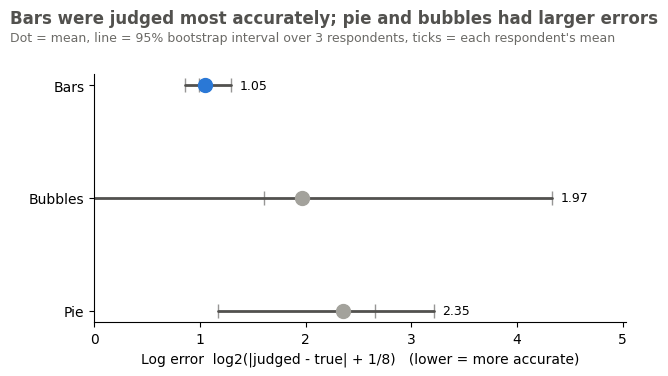

In [ ]:
# 4.4 Result chart: mean log error by encoding, 95% bootstrap interval over respondents
order = summary["mean_log_error"].sort_values().index.tolist()          # best (lowest error) first
fig, ax = plt.subplots(figsize=(7, 3.6))
for i, enc in enumerate(order):
    m = summary.loc[enc, "mean_log_error"]
    ax.plot(ci[enc], [i, i], color=DARK, lw=2, solid_capstyle="round")
    ax.plot(m, i, "o", color=BLUE if enc == order[0] else GREY, ms=10, zorder=3)
    ax.plot(per_resp.loc[enc].dropna(), [i] * per_resp.loc[enc].notna().sum(), "|", color=DARK, ms=10, alpha=.6)
    ax.text(ci[enc][1] + 0.08, i, f"{m:.2f}", va="center", fontsize=9)
ax.set_yticks(range(len(order)), [e.capitalize() for e in order]); ax.invert_yaxis()
ax.set_xlim(0, max(v[1] for v in ci.values()) + 0.7)
ax.set_xlabel("Log error  log2(|judged - true| + 1/8)   (lower = more accurate)")
ax.spines[["top", "right"]].set_visible(False)
n_resp = answers["respondent"].nunique()
fig.suptitle(f"Bars were judged most accurately; pie and bubbles had larger errors", x=0.02, ha="left", fontweight="bold", color=DARK)
fig.text(0.02, 0.89, f"Dot = mean, line = 95% bootstrap interval over {n_resp} respondents, ticks = each respondent's mean",
         fontsize=9, color="#6b6a66")
fig.subplots_adjust(top=0.8, left=0.14)
plt.show()

### 4.5 Interpretation (at most 150 words)
Our result agrees with Cleveland & McGill (1984) in direction: bars had the lowest mean log error (1.05), then bubbles (1.97) and pie (2.35). In points, the mean absolute error was 2.2 for bars, 6.8 for pie and 11.3 for bubbles. The bubble panel was hardest: R01 judged C, D and E as 50, 30 and 40 where the true values were 89, 65 and 78, while R02 and R03 were close. Bars were easiest; D was almost exact.

**Limitations.** (1) Only 3 respondents (36 estimates), so the intervals are wide and overlap; this is a first signal, not proof. (2) The sample is not random, screen sizes differed, and every respondent saw the panels in the same order, so fatigue may affect the last panel.

## Task 5 · The one-page figure
Three panels, one action title, consistent colours with Tasks 2-3.

In [ ]:
# Task 5: one figure, three panels, one action title
# TODO: write your code here

## Task 6 · Team and AI
| Member | What they did | Answers collected (Task 4) | Share of work |
|---|---|---|---|
| | | | |

In [ ]:
AI_USE = """
Tool(s) used:
What we asked:
What we checked or changed ourselves:
"""
print(AI_USE)